<a href="https://colab.research.google.com/github/maxsccavalcante/TCC/blob/main/TCC_pipeline_v0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC — Classificação de Melanoma com EfficientNetB0
## Notebook do pipeline — v0.1 (teste de fumaça)

**Autor:** Max Cavalcante — Ciência da Computação, Unipê
**Referência de implementação:** seção 2 (Materiais e Métodos) da proposta. Qualquer decisão de código aqui segue o que está escrito lá.

### Objetivo desta versão
Confirmar que o pipeline roda de ponta a ponta antes de gastar GPU com os experimentos de verdade:

1. carregar o HAM10000 e validar os metadados;
2. caracterizar o desbalanceamento (Etapa 1);
3. dividir 70/15/15 por `lesion_id`, estratificado pelo rótulo binário, e salvar a divisão;
4. treinar **apenas o baseline** (configuração 1), **uma semente (42)** e **poucas épocas**;
5. calcular as métricas do documento **somente na validação**.

### O que esta versão NÃO faz (de propósito)
- **Não usa o conjunto de teste.** Ele é separado na divisão e fica guardado até a Etapa 4, depois da escolha da estratégia.
- Não roda as configurações 2 (pesos de classe) e 3 (reamostragem + aumento de dados).
- Não define os hiperparâmetros finais: os valores da seção 0 são **provisórios**, só para o código rodar. Eles serão escolhidos nos testes preliminares (treino + validação) e depois congelados para as três configurações.
- Os números que saírem aqui **não são resultado do TCC**.

### Como rodar
- **Kaggle:** adicionar o dataset HAM10000 como *Input* do notebook, ativar a GPU e executar tudo. O código procura o `HAM10000_metadata.csv` dentro de `/kaggle/input`.
- **Google Colab:** ativar a GPU e executar tudo. O notebook tenta baixar o dataset com `kagglehub`, usando o identificador da variável `KAGGLE_DATASET` (seção 0). **Esse identificador precisa ser conferido no Kaggle antes de rodar.**
- **Qualquer ambiente:** se os arquivos já estiverem numa pasta, basta colocar o caminho em `DATA_DIR`.

| Seção do notebook | Seção do documento |
|---|---|
| 0. Configuração | 2 (parâmetros fixos do protocolo) |
| 1–3. Dados, validação e caracterização | 2.1 — Etapa 1 |
| 4. Divisão por `lesion_id` | 2 (divisão fixa 70/15/15) |
| 5–6. Pipeline de imagens e modelo | 2 e 2.2 |
| 7. Métricas | 2.2 e 3.5 |
| 8–9. Sementes e treino do baseline | 2.2 — Etapa 2 (versão curta) |

## 0. Configuração do ambiente e parâmetros do protocolo

Separei os parâmetros em dois grupos:

- **Fixos pelo documento** (tamanho da imagem, limiar, sementes, proporções da divisão). Não mudam em nenhum momento.
- **Hiperparâmetros (`HP`)**: provisórios nesta versão. O documento diz que eles saem de testes preliminares feitos só com treino e validação e que, depois de definidos, ficam iguais nas três configurações. Por isso eles ficam num único dicionário: quando forem definidos, basta mudar aqui.

A `SPLIT_SEED` é **separada** das sementes de treino. O documento diz que as sementes 42, 123 e 2026 controlam inicialização, embaralhamento, reamostragem e aumento de dados **sem alterar a divisão**. Com uma semente própria para a divisão, trocar a semente de treino nunca muda quem está no treino, na validação ou no teste.

In [1]:
import os
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, precision_score, f1_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score,
)

import tensorflow as tf
import keras
from keras import layers

print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas      :", pd.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU         :", gpus if gpus else "NENHUMA (o treino vai ficar lento; ative a GPU)")

Python      : 3.13.15
TensorFlow  : 2.21.0
Keras       : 3.13.2
scikit-learn: 1.6.1
pandas      : 2.2.3
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ===================== Parâmetros FIXOS (seção 2 do documento) =====================
IMG_SIZE = 224                       # imagens redimensionadas para 224 x 224
THRESHOLD = 0.5                      # limiar de classificação em todos os experimentos
SEEDS = [42, 123, 2026]              # sementes de treino (inicialização, embaralhamento, reamostragem, aumento)
SPLIT_SEED = 42                      # semente APENAS da divisão treino/validação/teste (fixa)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
POSITIVE_DX = "mel"                  # melanoma = classe positiva (1); as outras 6 categorias = não melanoma (0)

# ============ Hiperparâmetros PROVISÓRIOS (só para o teste de fumaça) ============
# Serão definidos nos testes preliminares (treino + validação) e depois CONGELADOS
# para as três configurações.
HP = {
    "batch_size": 32,
    "learning_rate": 1e-3,
    "max_epochs": 3,          # poucas épocas: aqui só queremos ver o pipeline rodar
    "patience": 2,            # paciência do early stopping
    "dropout": 0.0,           # 0.0 = sem dropout (o documento não prevê dropout; fica como opção dos testes preliminares)
    "freeze_base": True,      # base congelada (só a cabeça treina) nesta versão; decisão dos testes preliminares
}
SMOKE_SEED = 42               # nesta versão roda só uma semente

# ===================== Caminhos =====================
DATA_DIR = None               # caminho da pasta com o HAM10000; None = procurar em /kaggle/input ou baixar
KAGGLE_DATASET = "kmader/skin-cancer-mnist-ham10000"   # CONFERIR no Kaggle antes de usar no Colab
DETERMINISTIC_OPS = False     # True liga tf.config.experimental.enable_op_determinism() (ver seção 8)

if Path("/kaggle/working").exists():
    OUTPUT_DIR = Path("/kaggle/working/tcc_outputs")
elif Path("/content").exists():
    OUTPUT_DIR = Path("/content/tcc_outputs")
else:
    OUTPUT_DIR = Path("tcc_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saídas em:", OUTPUT_DIR.resolve())

# Lista de checagens: cada verificação do notebook é registrada aqui e resumida no final.
CHECAGENS = []

def verificar(condicao, descricao, critica=True):
    # Registra uma checagem. Se for crítica e falhar, interrompe o notebook.
    ok = bool(condicao)
    CHECAGENS.append({"checagem": descricao, "ok": ok, "critica": critica})
    print(("OK    " if ok else ("FALHOU" if critica else "AVISO ")) + " | " + descricao)
    if critica and not ok:
        raise AssertionError("Checagem crítica falhou: " + descricao)

Saídas em: /content/tcc_outputs


## 1. Obter o HAM10000

O código procura o arquivo `HAM10000_metadata.csv` em vez de depender de um caminho fixo, porque a estrutura de pastas pode mudar entre ambientes. Ordem de busca: `DATA_DIR` (se preenchido) → `/kaggle/input` → download com `kagglehub`.

Depois, todos os `.jpg` encontrados são mapeados pelo nome do arquivo (`image_id`). Se o mesmo `image_id` aparecer em mais de uma pasta, só o primeiro caminho é guardado, para cada imagem entrar uma única vez.

In [3]:
def localizar_ham10000(data_dir=None):
    bases = [Path(data_dir)] if data_dir else [Path("/kaggle/input")]
    for base in bases:
        if base.exists():
            achados = sorted(base.rglob("HAM10000_metadata.csv"))
            if achados:
                return achados[0].parent
    if data_dir:
        raise FileNotFoundError(f"HAM10000_metadata.csv não encontrado em {data_dir}")
    import kagglehub  # Colab / máquina local
    baixado = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    achados = sorted(baixado.rglob("HAM10000_metadata.csv"))
    if not achados:
        raise FileNotFoundError("Download concluído, mas HAM10000_metadata.csv não foi encontrado.")
    return achados[0].parent

DATA_ROOT = localizar_ham10000(DATA_DIR)
print("Dados em:", DATA_ROOT)

caminhos = {}
for p in sorted(DATA_ROOT.rglob("*.jpg")):
    caminhos.setdefault(p.stem, str(p))
print("Arquivos .jpg únicos encontrados:", len(caminhos))

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Dados em: /kaggle/input/skin-cancer-mnist-ham10000
Arquivos .jpg únicos encontrados: 10015


## 2. Metadados e rótulo binário

Cada linha do `HAM10000_metadata.csv` é uma **imagem** (`image_id`). A coluna `lesion_id` identifica a **lesão**: uma mesma lesão pode ter várias imagens. A coluna `dx` tem a categoria diagnóstica (7 valores).

Rótulo binário: `label = 1` se `dx == "mel"` (melanoma), `label = 0` para as outras seis categorias (não melanoma).

In [4]:
meta = pd.read_csv(DATA_ROOT / "HAM10000_metadata.csv")
meta["label"] = (meta["dx"] == POSITIVE_DX).astype(int)
meta["path"] = meta["image_id"].map(caminhos)
print(meta.shape)
meta.head()

(10015, 9)


,lesion_id,image_id,dx,dx_type,age,sex,localization,label,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,0,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,0,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,0,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,0,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,0,/kaggle/input/skin-cancer-mnist-ham10000/HAM10...


### 2.1 Validação dos metadados (validação da Etapa 1)

O documento pede três conferências: integridade dos metadados, correspondência entre registros e arquivos, e ausência de duplicações indevidas. Também pede comparar a distribuição com os números publicados (≈1.113 melanoma e 8.902 não melanoma).

Acrescentei uma quarta checagem, que é condição para a divisão por lesão funcionar: **cada `lesion_id` precisa ter um único diagnóstico**. Se uma lesão tivesse imagens com rótulos diferentes, não daria para estratificar a divisão pelo rótulo da lesão.

As checagens críticas param o notebook se falharem. A comparação com os números publicados é só um aviso.

In [5]:
colunas = {"lesion_id", "image_id", "dx"}
verificar(colunas.issubset(meta.columns), "colunas lesion_id, image_id e dx presentes")
verificar(meta[list(colunas)].notna().all().all(), "sem valores nulos em lesion_id, image_id e dx")
verificar(not meta["image_id"].duplicated().any(), "nenhum image_id duplicado")
verificar(meta["path"].notna().all(),
          f"todo registro tem arquivo de imagem ({meta['path'].isna().sum()} sem arquivo)")
sobrando = set(caminhos) - set(meta["image_id"])
verificar(len(sobrando) == 0, f"nenhum .jpg sem registro nos metadados ({len(sobrando)} sobrando)", critica=False)

dx_por_lesao = meta.groupby("lesion_id")["dx"].nunique()
verificar((dx_por_lesao == 1).all(),
          f"cada lesion_id tem um único diagnóstico ({(dx_por_lesao > 1).sum()} lesões inconsistentes)")

n_total, n_mel = len(meta), int(meta["label"].sum())
verificar(n_total == 10015, f"total de imagens = 10.015 (encontrado: {n_total})", critica=False)
verificar(n_mel == 1113, f"imagens de melanoma = 1.113 (encontrado: {n_mel})", critica=False)
verificar(n_total - n_mel == 8902, f"imagens de não melanoma = 8.902 (encontrado: {n_total - n_mel})", critica=False)

from PIL import Image
with Image.open(meta["path"].iloc[0]) as im:
    print("\nExemplo de imagem original (largura x altura, modo):", im.size, im.mode)

OK     | colunas lesion_id, image_id e dx presentes
OK     | sem valores nulos em lesion_id, image_id e dx
OK     | nenhum image_id duplicado
OK     | todo registro tem arquivo de imagem (0 sem arquivo)
OK     | nenhum .jpg sem registro nos metadados (0 sobrando)
OK     | cada lesion_id tem um único diagnóstico (0 lesões inconsistentes)
OK     | total de imagens = 10.015 (encontrado: 10015)
OK     | imagens de melanoma = 1.113 (encontrado: 1113)
OK     | imagens de não melanoma = 8.902 (encontrado: 8902)

Exemplo de imagem original (largura x altura, modo): (600, 450) RGB


## 3. Caracterização do desbalanceamento (Etapa 1)

Conto **imagens** e **lesões** porque as duas coisas importam: o modelo é treinado com imagens, mas a divisão é feita por lesão. A razão de desbalanceamento é `não melanoma / melanoma`.

A última linha calcula a acurácia de um classificador que responde "não melanoma" para tudo. A seção 3.5 do documento cita esse valor (cerca de 88,9%); aqui ele é recalculado com os dados reais.

A tabela usa os códigos da coluna `dx` exatamente como vêm nos metadados. A correspondência entre cada código e o nome da categoria (seção 3.2 do documento) deve ser conferida em Tschandl, Rosendahl e Kittler (2018) antes de ir para o texto.

In [6]:
tab_dx = (meta.groupby("dx")
          .agg(imagens=("image_id", "size"), lesoes=("lesion_id", "nunique"))
          .sort_values("imagens", ascending=False))
tab_dx["% imagens"] = (100 * tab_dx["imagens"] / tab_dx["imagens"].sum()).round(2)
tab_dx["% lesões"] = (100 * tab_dx["lesoes"] / tab_dx["lesoes"].sum()).round(2)
tab_dx["imagens por lesão"] = (tab_dx["imagens"] / tab_dx["lesoes"]).round(2)

lesoes = (meta.groupby("lesion_id", as_index=False)
          .agg(label=("label", "max"), n_imagens=("image_id", "size")))

classe = {1: "melanoma", 0: "não melanoma"}
tab_bin = pd.DataFrame({
    "imagens": meta["label"].map(classe).value_counts(),
    "lesoes": lesoes["label"].map(classe).value_counts(),
}).loc[["melanoma", "não melanoma"]]
tab_bin["% imagens"] = (100 * tab_bin["imagens"] / tab_bin["imagens"].sum()).round(2)
tab_bin["% lesões"] = (100 * tab_bin["lesoes"] / tab_bin["lesoes"].sum()).round(2)

razao_img = tab_bin.loc["não melanoma", "imagens"] / tab_bin.loc["melanoma", "imagens"]
razao_les = tab_bin.loc["não melanoma", "lesoes"] / tab_bin.loc["melanoma", "lesoes"]
acc_trivial = tab_bin.loc["não melanoma", "imagens"] / tab_bin["imagens"].sum()

display(tab_dx)
display(tab_bin)
print(f"Razão de desbalanceamento (imagens): 1 melanoma : {razao_img:.2f} não melanoma")
print(f"Razão de desbalanceamento (lesões) : 1 melanoma : {razao_les:.2f} não melanoma")
print(f"Acurácia de quem responde sempre 'não melanoma': {100 * acc_trivial:.1f}%")

tab_dx.to_csv(OUTPUT_DIR / "etapa1_tabela_por_categoria.csv")
tab_bin.to_csv(OUTPUT_DIR / "etapa1_tabela_binaria.csv")

,imagens,lesoes,% imagens,% lesões,imagens por lesão
dx,,,,,
nv,6705,5403,66.95,72.33,1.24
mel,1113,614,11.11,8.22,1.81
bkl,1099,727,10.97,9.73,1.51
bcc,514,327,5.13,4.38,1.57
akiec,327,228,3.27,3.05,1.43
vasc,142,98,1.42,1.31,1.45
df,115,73,1.15,0.98,1.58


,imagens,lesoes,% imagens,% lesões
label,,,,
melanoma,1113,614,11.11,8.22
não melanoma,8902,6856,88.89,91.78


Razão de desbalanceamento (imagens): 1 melanoma : 8.00 não melanoma
Razão de desbalanceamento (lesões) : 1 melanoma : 11.17 não melanoma
Acurácia de quem responde sempre 'não melanoma': 88.9%


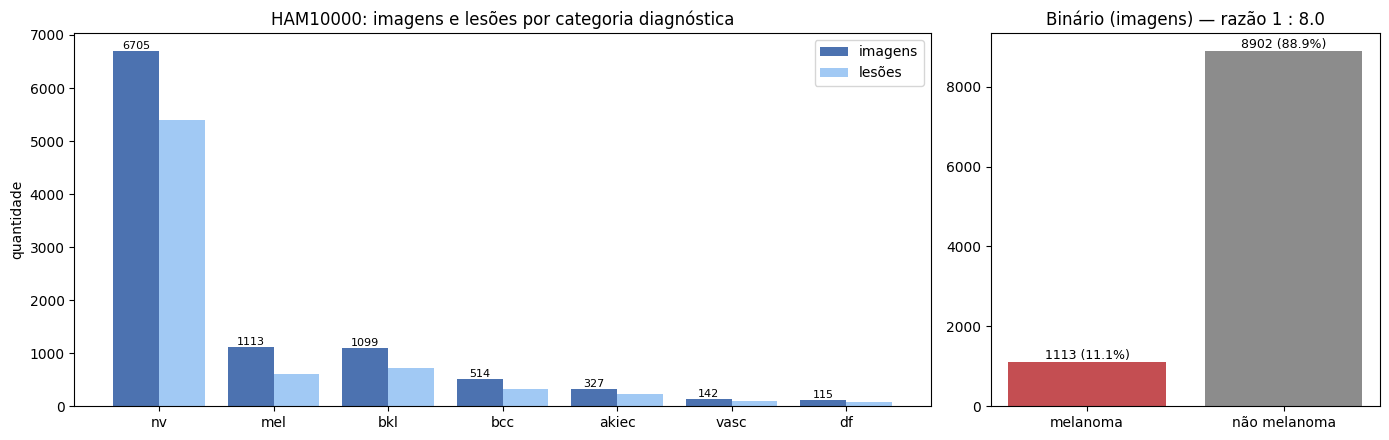

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

ordem = tab_dx.index.tolist()
x = np.arange(len(ordem))
eixos[0].bar(x - 0.2, tab_dx["imagens"], width=0.4, label="imagens", color="#4C72B0")
eixos[0].bar(x + 0.2, tab_dx["lesoes"], width=0.4, label="lesões", color="#A1C9F4")
eixos[0].set_xticks(x, ordem)
eixos[0].set_title("HAM10000: imagens e lesões por categoria diagnóstica")
eixos[0].set_ylabel("quantidade")
eixos[0].legend()
for i, v in enumerate(tab_dx["imagens"]):
    eixos[0].text(i - 0.2, v, f"{v}", ha="center", va="bottom", fontsize=8)

cores = ["#C44E52", "#8C8C8C"]
eixos[1].bar(tab_bin.index, tab_bin["imagens"], color=cores)
eixos[1].set_title(f"Binário (imagens) — razão 1 : {razao_img:.1f}")
for i, v in enumerate(tab_bin["imagens"]):
    eixos[1].text(i, v, f"{v} ({tab_bin['% imagens'].iloc[i]:.1f}%)", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "etapa1_distribuicao.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Divisão 70/15/15 por `lesion_id`, estratificada pelo rótulo binário

Por que por lesão: se a divisão fosse por imagem, fotos da mesma lesão poderiam cair uma no treino e outra no teste. O modelo "reconheceria" a lesão em vez de aprender o padrão do melanoma, e as métricas sairiam otimistas demais (vazamento de dados).

Como é feito, exatamente como no documento:

1. monta-se uma tabela com **uma linha por `lesion_id`** e seu rótulo binário (já feita na seção 3: `lesoes`);
2. separa-se 70% das lesões para treino e 30% para um conjunto temporário, estratificando pelo rótulo;
3. o temporário é dividido ao meio (15% validação, 15% teste), também estratificado;
4. cada imagem herda o conjunto da sua lesão.

Os 70/15/15 valem para **lesões**. Em imagens a proporção fica muito próxima disso, mas não idêntica, porque lesões têm quantidades diferentes de imagens. A tabela abaixo mostra os números reais.

**Mesma divisão em todos os experimentos:** a divisão é salva em `divisao_lesion_id.csv`. Se o arquivo já existir, o notebook recalcula e confere se deu exatamente igual. Esse CSV deve ir junto com o notebook para o grupo: é ele que garante que todo mundo usa a mesma divisão.

In [8]:
les_train, les_temp = train_test_split(
    lesoes, test_size=VAL_FRAC + TEST_FRAC, stratify=lesoes["label"], random_state=SPLIT_SEED)
les_val, les_test = train_test_split(
    les_temp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=les_temp["label"], random_state=SPLIT_SEED)

mapa_split = {}
mapa_split.update(dict.fromkeys(les_train["lesion_id"], "train"))
mapa_split.update(dict.fromkeys(les_val["lesion_id"], "val"))
mapa_split.update(dict.fromkeys(les_test["lesion_id"], "test"))
meta["split"] = meta["lesion_id"].map(mapa_split)

# --- checagens de vazamento e cobertura ---
tr, va, te = set(les_train["lesion_id"]), set(les_val["lesion_id"]), set(les_test["lesion_id"])
verificar(not (tr & va) and not (tr & te) and not (va & te), "nenhuma lesão aparece em dois conjuntos")
verificar(meta["split"].notna().all(), "toda imagem recebeu um conjunto")
verificar((meta.groupby("lesion_id")["split"].nunique() == 1).all(),
          "todas as imagens de cada lesão estão no mesmo conjunto")

# --- salvar / conferir a divisão fixa ---
arquivo_split = OUTPUT_DIR / "divisao_lesion_id.csv"
divisao = meta[["image_id", "lesion_id", "dx", "label", "split"]].sort_values("image_id").reset_index(drop=True)
if arquivo_split.exists():
    salva = pd.read_csv(arquivo_split).sort_values("image_id").reset_index(drop=True)
    verificar(salva[["image_id", "split"]].equals(divisao[["image_id", "split"]]),
              "divisão recalculada é idêntica à divisão salva")
else:
    divisao.to_csv(arquivo_split, index=False)
    print("Divisão salva em", arquivo_split)

# --- resumo ---
resumo = (meta.groupby("split")
          .agg(lesoes=("lesion_id", "nunique"), imagens=("image_id", "size"), melanoma=("label", "sum"))
          .loc[["train", "val", "test"]])
resumo["não melanoma"] = resumo["imagens"] - resumo["melanoma"]
resumo["% melanoma"] = (100 * resumo["melanoma"] / resumo["imagens"]).round(2)
resumo["% das lesões"] = (100 * resumo["lesoes"] / resumo["lesoes"].sum()).round(2)
resumo["% das imagens"] = (100 * resumo["imagens"] / resumo["imagens"].sum()).round(2)
resumo.to_csv(OUTPUT_DIR / "divisao_resumo.csv")
display(resumo)

df_train = meta[meta["split"] == "train"].reset_index(drop=True)
df_val = meta[meta["split"] == "val"].reset_index(drop=True)
df_test = meta[meta["split"] == "test"].reset_index(drop=True)
# ATENÇÃO: df_test fica guardado. Nenhuma célula deste notebook cria dataset, prediz ou
# calcula métrica com ele. Ele só será usado na Etapa 4, depois da escolha da estratégia.

OK     | nenhuma lesão aparece em dois conjuntos
OK     | toda imagem recebeu um conjunto
OK     | todas as imagens de cada lesão estão no mesmo conjunto
Divisão salva em /content/tcc_outputs/divisao_lesion_id.csv


,lesoes,imagens,melanoma,não melanoma,% melanoma,% das lesões,% das imagens
split,,,,,,,
train,5229,7000,774,6226,11.06,70.00,69.90
val,1120,1505,172,1333,11.43,14.99,15.03
test,1121,1510,167,1343,11.06,15.01,15.08


## 5. Pipeline de imagens (`tf.data`) — sem normalizar duas vezes

Este é o ponto mais fácil de errar, e o documento cita explicitamente: **não aplicar a normalização duas vezes**.

A documentação do Keras para a EfficientNet diz que o pré-processamento de entrada já faz parte do modelo (como uma camada `Rescaling`), que `keras.applications.efficientnet.preprocess_input` não altera a entrada e que o modelo espera pixels em `float` na faixa **[0-255]** ([Keras — EfficientNet models](https://keras.io/api/applications/efficientnet/efficientnet_models/)). Se o pipeline dividisse por 255, a imagem chegaria ao modelo fora da faixa esperada, e o código não avisaria.

Por isso o pipeline aqui só faz: ler o JPEG → redimensionar para 224 × 224 → converter para `float32`, mantendo [0, 255]. A checagem logo abaixo confirma a faixa de valores, e a seção 6 lista as primeiras camadas do modelo para confirmar a `Rescaling` interna.

Detalhes:
- O redimensionamento vai direto para 224 × 224, como diz o documento. O tamanho original de uma imagem é impresso na seção 2.1.
- As imagens redimensionadas ficam em cache na memória como `uint8`, para não reler o disco a cada época. Se a RAM do ambiente não for suficiente, troque `.cache()` por `.cache("arquivo_em_disco")`.
- Só o treino é embaralhado, com a semente da execução. Validação e teste mantêm a ordem, para as previsões baterem com os rótulos.
- Nesta versão não há aumento de dados nem reamostragem (baseline).

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def carregar_imagem(caminho, rotulo):
    img = tf.io.read_file(caminho)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))           # float32 em [0, 255]
    img = tf.cast(tf.clip_by_value(tf.round(img), 0.0, 255.0), tf.uint8)  # uint8 economiza memória no cache
    return img, rotulo

def para_float(img, rotulo):
    return tf.cast(img, tf.float32), rotulo                   # continua em [0, 255]: NÃO normaliza aqui

def criar_dataset(df, treino, seed, batch_size):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values.astype("float32")))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE).cache()
    if treino:
        ds = ds.shuffle(len(df), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(batch_size).map(para_float, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Checagem rápida num lote de validação
ds_check = criar_dataset(df_val.head(64), treino=False, seed=SMOKE_SEED, batch_size=32)
imgs, rots = next(iter(ds_check))
print("formato do lote:", imgs.shape, imgs.dtype)
print(f"faixa de pixels: min={float(tf.reduce_min(imgs)):.1f}  max={float(tf.reduce_max(imgs)):.1f}")
verificar(imgs.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), "imagens chegam em 224 x 224 x 3")
verificar(float(tf.reduce_max(imgs)) > 1.5, "pixels chegam ao modelo em [0, 255] (sem divisão por 255 no pipeline)")

formato do lote: (32, 224, 224, 3) <dtype: 'float32'>
faixa de pixels: min=0.0  max=255.0
OK     | imagens chegam em 224 x 224 x 3
OK     | pixels chegam ao modelo em [0, 255] (sem divisão por 255 no pipeline)


### 5.1 Verificação visual: imagem original × imagem que entra no modelo

Mostra uma imagem de cada código `dx`, sorteada do **conjunto de treino** (validação e teste não são usados aqui). Na linha de cima está o arquivo original; na de baixo, a mesma imagem depois de `carregar_imagem`, ou seja, exatamente como ela entra no modelo.

Serve para duas coisas:
- conferir a olho que o pré-processamento não estragou as imagens (cores, orientação, conteúdo);
- ver a heterogeneidade da classe "não melanoma", citada nas seções 2 e 3.2 do documento.

O redimensionamento direto para 224 × 224 é o que o documento define. Se a imagem original não for quadrada (o tamanho de uma delas é impresso na seção 2.1), a proporção muda; a figura deixa isso visível.

Antes de usar esta figura no texto do TCC, confirmar se a licença do HAM10000 permite reproduzir as imagens.

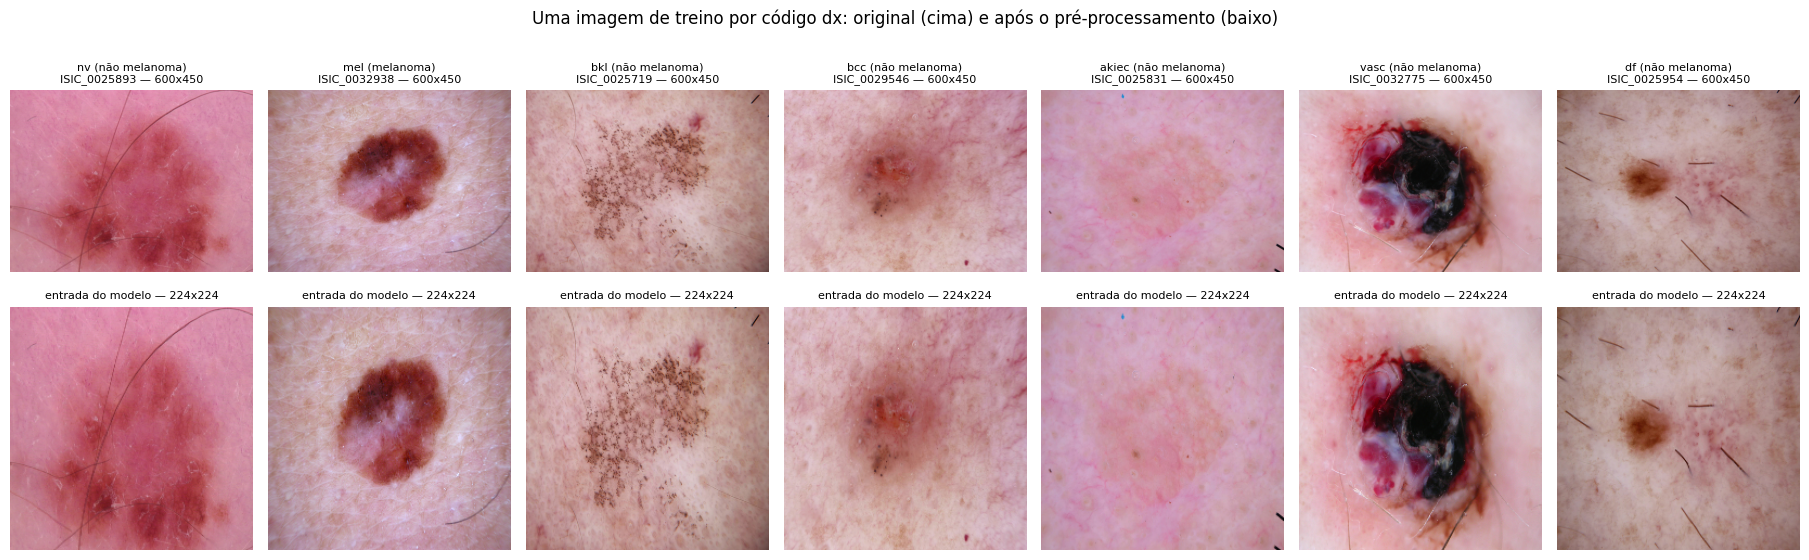

In [10]:
from PIL import Image

codigos = meta["dx"].value_counts().index.tolist()
exemplos = [df_train[df_train["dx"] == c].sample(1, random_state=SPLIT_SEED).iloc[0] for c in codigos]

fig, eixos = plt.subplots(2, len(exemplos), figsize=(2.6 * len(exemplos), 5.8))
for j, ex in enumerate(exemplos):
    with Image.open(ex["path"]) as im:
        eixos[0, j].imshow(im.convert("RGB"))
        largura, altura = im.size
    img_modelo, _ = carregar_imagem(tf.constant(ex["path"]), tf.constant(0.0))
    eixos[1, j].imshow(img_modelo.numpy())
    rotulo = "melanoma" if ex["label"] == 1 else "não melanoma"
    eixos[0, j].set_title(f'{ex["dx"]} ({rotulo})\n{ex["image_id"]} — {largura}x{altura}', fontsize=8)
    eixos[1, j].set_title(f"entrada do modelo — {IMG_SIZE}x{IMG_SIZE}", fontsize=8)
for e in eixos.ravel():
    e.axis("off")
fig.suptitle("Uma imagem de treino por código dx: original (cima) e após o pré-processamento (baixo)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "etapa1_exemplos_imagens.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Modelo: EfficientNetB0 pré-treinada no ImageNet

Estrutura:
- `EfficientNetB0(include_top=False, weights="imagenet")`: a rede sem a camada de classificação original (que tinha 1.000 classes do ImageNet);
- `GlobalAveragePooling2D`: transforma o mapa de características da base em um vetor;
- `Dropout`: com taxa 0.0 nesta versão (não faz nada). O documento não prevê dropout; a camada só existe para que os testes preliminares possam testá-lo sem mudar o código;
- `Dense(1, sigmoid)`: a "camada de saída adequada à classificação binária" do documento. A saída é a probabilidade de melanoma; com o limiar 0,5, `p ≥ 0,5` vira melanoma.

A base é chamada com `training=False`. O guia de transferência de aprendizado do Keras recomenda isso para manter as camadas `BatchNormalization` em modo de inferência quando a base for descongelada para fine-tuning ([Keras — Transfer learning & fine-tuning](https://keras.io/guides/transfer_learning/)).

Nesta versão a base está congelada (`freeze_base=True`): só a cabeça é treinada. Congelar ou não, e quantas camadas descongelar, é decisão dos testes preliminares.

In [11]:
def construir_modelo(hp):
    base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = not hp["freeze_base"]

    entradas = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="imagem_0_255")
    x = base(entradas, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(hp["dropout"], name="dropout")(x)
    saidas = layers.Dense(1, activation="sigmoid", name="prob_melanoma")(x)
    modelo = keras.Model(entradas, saidas, name="efficientnetb0_binario")

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp["learning_rate"]),
        loss=keras.losses.BinaryCrossentropy(),
        # métricas só para acompanhar as curvas; as métricas oficiais são calculadas com scikit-learn (seção 7)
        metrics=[
            keras.metrics.AUC(curve="ROC", name="auc_roc"),
            keras.metrics.AUC(curve="PR", name="auc_pr"),
            keras.metrics.Recall(thresholds=THRESHOLD, name="recall"),
            keras.metrics.Precision(thresholds=THRESHOLD, name="precision"),
        ],
    )
    return modelo

modelo_teste = construir_modelo(HP)
base_teste = [l for l in modelo_teste.layers if isinstance(l, keras.Model)][0]
primeiras = [type(l).__name__ for l in base_teste.layers[:5]]
print("Primeiras camadas da EfficientNetB0:", primeiras)
verificar("Rescaling" in primeiras,
          "a EfficientNetB0 tem camada Rescaling interna → o pipeline não deve normalizar")
treinaveis = int(sum(np.prod(v.shape) for v in modelo_teste.trainable_weights))
print(f"Parâmetros treináveis: {treinaveis:,}  (base congelada = só a cabeça)")
del modelo_teste, base_teste

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Primeiras camadas da EfficientNetB0: ['InputLayer', 'Rescaling', 'Normalization', 'Rescaling', 'ZeroPadding2D']
OK     | a EfficientNetB0 tem camada Rescaling interna → o pipeline não deve normalizar
Parâmetros treináveis: 1,281  (base congelada = só a cabeça)


## 7. Métricas do documento

Todas calculadas com scikit-learn sobre as previsões, com **melanoma como classe positiva**:

| Métrica | Fórmula | Usa limiar 0,5? |
|---|---|---|
| Sensibilidade (recall de melanoma) | TP / (TP + FN) | sim |
| Especificidade | TN / (TN + FP) | sim |
| Precisão | TP / (TP + FP) | sim |
| F1 | média harmônica de precisão e sensibilidade | sim |
| Acurácia balanceada | (sensibilidade + especificidade) / 2 | sim |
| AUC-ROC | área sob a curva ROC | não (usa as probabilidades) |
| AUC-PR | área sob a curva precisão-recall (*average precision*) | não (usa as probabilidades) |
| Matriz de confusão | TP, FP, TN, FN | sim |

A AUC-PR é calculada com a função `average_precision_score` do scikit-learn. Como existe mais de uma forma de calcular a área sob a curva precisão-recall, o texto do TCC deve dizer qual função foi usada.

Para cada configuração, a média e o desvio-padrão são calculados sobre as três sementes. O desvio é o amostral (n − 1), padrão do pandas.

A célula termina com um teste da própria função num exemplo pequeno com resposta conhecida, para garantir que a fórmula está certa antes de usar nos experimentos.

In [12]:
METRICAS = ["sensibilidade", "especificidade", "precisao", "f1",
            "acuracia_balanceada", "auc_roc", "auc_pr"]

def calcular_metricas(y_true, y_prob, limiar=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    y_pred = (y_prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "sensibilidade": tp / (tp + fn) if (tp + fn) else np.nan,
        "especificidade": tn / (tn + fp) if (tn + fp) else np.nan,
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "acuracia_balanceada": balanced_accuracy_score(y_true, y_pred),
        "auc_roc": roc_auc_score(y_true, y_prob),
        "auc_pr": average_precision_score(y_true, y_prob),
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
    }

def resumir_sementes(df_resultados):
    # média e desvio-padrão (n-1) de cada métrica, por configuração
    return df_resultados.groupby("configuracao")[METRICAS].agg(["mean", "std"])

# Teste da função: 4 exemplos, resposta conhecida
m = calcular_metricas([1, 1, 0, 0], [0.9, 0.4, 0.6, 0.1])
verificar((m["tp"], m["fn"], m["fp"], m["tn"]) == (1, 1, 1, 1), "matriz de confusão do exemplo = (TP1, FN1, FP1, TN1)")
verificar(np.isclose(m["sensibilidade"], 0.5) and np.isclose(m["especificidade"], 0.5)
          and np.isclose(m["acuracia_balanceada"], 0.5), "sensibilidade, especificidade e acurácia balanceada do exemplo = 0,5")
verificar(np.isclose(m["auc_roc"], 0.75), "AUC-ROC do exemplo = 0,75")

OK     | matriz de confusão do exemplo = (TP1, FN1, FP1, TN1)
OK     | sensibilidade, especificidade e acurácia balanceada do exemplo = 0,5
OK     | AUC-ROC do exemplo = 0,75


## 8. Reprodutibilidade: fixando a semente

`keras.utils.set_random_seed(seed)` fixa de uma vez as sementes do Python, do NumPy e do TensorFlow. Com isso, a mesma semente gera a mesma inicialização da cabeça do modelo, o mesmo embaralhamento e, nas próximas versões, a mesma reamostragem e o mesmo aumento de dados.

A opção `DETERMINISTIC_OPS = True` liga também `tf.config.experimental.enable_op_determinism()`. Deixei desligada por padrão. Antes de decidir usá-la, consultar a documentação oficial do TensorFlow sobre essa função. Uma forma prática de verificar a reprodutibilidade no próprio ambiente é rodar a mesma semente duas vezes e comparar as métricas.

In [13]:
def fixar_semente(seed):
    keras.utils.set_random_seed(seed)   # Python + NumPy + TensorFlow
    if DETERMINISTIC_OPS:
        tf.config.experimental.enable_op_determinism()

## 9. Teste de fumaça: baseline (configuração 1), semente 42, poucas épocas

**Baseline = sem pesos de classe, sem reamostragem e sem aumento de dados.** Por isso a função abaixo é chamada com `class_weight=None` e com o dataset de treino "puro".

O early stopping monitora a **perda de validação** (`val_loss`) com `restore_best_weights=True`, como no documento.

Um cuidado extra: a documentação do `EarlyStopping` ([Keras — EarlyStopping](https://keras.io/api/callbacks/early_stopping)) explica o `restore_best_weights`, mas não diz explicitamente o que acontece quando o treino chega ao número máximo de épocas sem parar antes. Para não depender disso, um `ModelCheckpoint` também salva os pesos da época com menor `val_loss`, e esses pesos são carregados no fim. Depois, uma checagem recalcula a perda de validação do modelo final e confere se ela é igual à menor `val_loss` do histórico. Assim fica comprovado, na própria execução, que o modelo avaliado é o da melhor época.

Depois do treino, o modelo prevê as probabilidades da **validação** e as métricas são calculadas com limiar 0,5.

A função já foi escrita pensando nas próximas versões: o parâmetro `class_weight` vai servir para a configuração 2, e a configuração 3 vai trocar só o dataset de treino.

In [14]:
def treinar_e_avaliar(configuracao, seed, hp, class_weight=None):
    keras.backend.clear_session()
    fixar_semente(seed)

    ds_train = criar_dataset(df_train, treino=True, seed=seed, batch_size=hp["batch_size"])
    ds_val = criar_dataset(df_val, treino=False, seed=seed, batch_size=hp["batch_size"])
    modelo = construir_modelo(hp)

    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=hp["patience"], restore_best_weights=True, verbose=1)
    arquivo_pesos = OUTPUT_DIR / f"melhores_pesos_{configuracao}_seed{seed}.weights.h5"
    melhor = keras.callbacks.ModelCheckpoint(
        str(arquivo_pesos), monitor="val_loss", save_best_only=True, save_weights_only=True)
    inicio = time.time()
    hist = modelo.fit(ds_train, validation_data=ds_val, epochs=hp["max_epochs"],
                      callbacks=[parada, melhor], class_weight=class_weight, verbose=2)
    duracao = time.time() - inicio

    modelo.load_weights(str(arquivo_pesos))      # garante os pesos da época com menor val_loss
    val_loss_final = modelo.evaluate(ds_val, verbose=0, return_dict=True)["loss"]
    val_loss_melhor = float(np.min(hist.history["val_loss"]))
    print(f"val_loss do modelo final = {val_loss_final:.5f} | menor val_loss do histórico = {val_loss_melhor:.5f}")
    verificar(np.isclose(val_loss_final, val_loss_melhor, rtol=1e-3, atol=1e-4),
              f"[{configuracao}/{seed}] modelo avaliado tem os pesos da melhor época (menor val_loss)")

    y_prob_val = modelo.predict(ds_val, verbose=0).ravel()
    verificar(len(y_prob_val) == len(df_val), f"[{configuracao}/{seed}] uma previsão por imagem de validação")

    met = calcular_metricas(df_val["label"].values, y_prob_val)
    met.update({
        "configuracao": configuracao, "semente": seed, "conjunto": "validacao",
        "epocas_treinadas": len(hist.history["loss"]),
        "melhor_epoca": int(np.argmin(hist.history["val_loss"])) + 1,
        "segundos": round(duracao, 1),
    })
    return modelo, hist, met, y_prob_val

modelo_bl, hist_bl, met_bl, prob_val_bl = treinar_e_avaliar("baseline", SMOKE_SEED, HP)

Epoch 1/3
219/219 - 133s - 607ms/step - auc_pr: 0.1993 - auc_roc: 0.7260 - loss: 0.3246 - precision: 0.2171 - recall: 0.0362 - val_auc_pr: 0.3285 - val_auc_roc: 0.8065 - val_loss: 0.2930 - val_precision: 0.6667 - val_recall: 0.0581
Epoch 2/3
219/219 - 10s - 45ms/step - auc_pr: 0.3492 - auc_roc: 0.8240 - loss: 0.2784 - precision: 0.5421 - recall: 0.0749 - val_auc_pr: 0.3953 - val_auc_roc: 0.8325 - val_loss: 0.2773 - val_precision: 0.7500 - val_recall: 0.1047
Epoch 3/3
219/219 - 10s - 45ms/step - auc_pr: 0.4062 - auc_roc: 0.8420 - loss: 0.2665 - precision: 0.5893 - recall: 0.1279 - val_auc_pr: 0.4309 - val_auc_roc: 0.8409 - val_loss: 0.2743 - val_precision: 0.7600 - val_recall: 0.1105
Restoring model weights from the end of the best epoch: 3.
val_loss do modelo final = 0.27426 | menor val_loss do histórico = 0.27426
OK     | [baseline/42] modelo avaliado tem os pesos da melhor época (menor val_loss)
OK     | [baseline/42] uma previsão por imagem de validação


In [15]:
resultado = pd.DataFrame([met_bl])
colunas_ordem = ["configuracao", "semente", "conjunto"] + METRICAS + ["tp", "fp", "tn", "fn",
                 "epocas_treinadas", "melhor_epoca", "segundos"]
resultado = resultado[colunas_ordem]
resultado.to_csv(OUTPUT_DIR / "smoke_baseline_seed42_validacao.csv", index=False)
pd.DataFrame(hist_bl.history).to_csv(OUTPUT_DIR / "smoke_baseline_seed42_historico.csv", index_label="epoca")
display(resultado.round(4))
print("Lembrete: hiperparâmetros provisórios, poucas épocas e uma semente. NÃO é resultado do TCC.")

,configuracao,semente,conjunto,sensibilidade,especificidade,precisao,f1,acuracia_balanceada,auc_roc,auc_pr,tp,fp,tn,fn,epocas_treinadas,melhor_epoca,segundos
0,baseline,42,validacao,0.1105,0.9955,0.76,0.1929,0.553,0.8412,0.4322,19,6,1327,153,3,3,153.0


Lembrete: hiperparâmetros provisórios, poucas épocas e uma semente. NÃO é resultado do TCC.


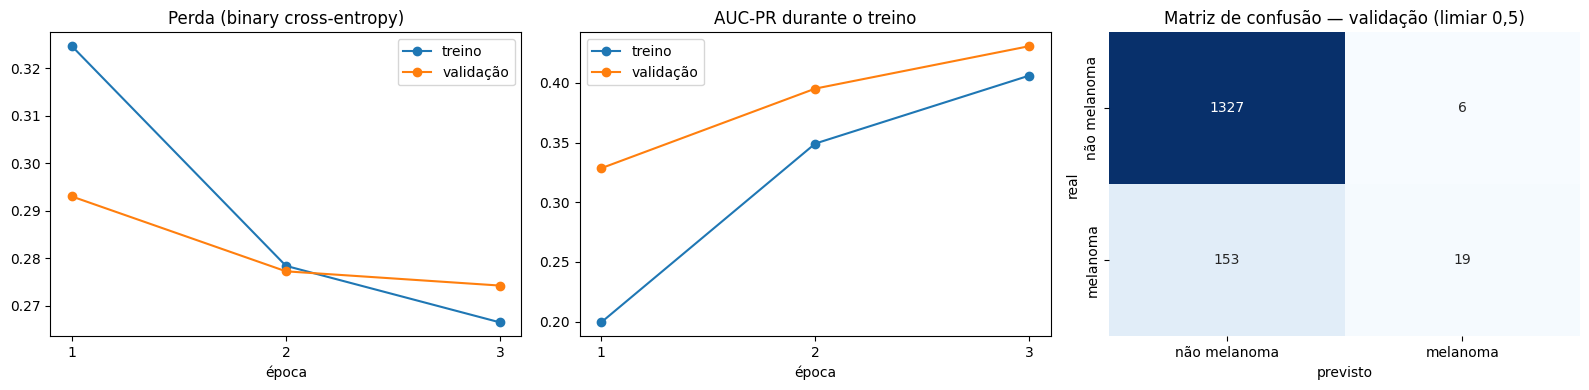

In [16]:
h = pd.DataFrame(hist_bl.history)
epocas = np.arange(1, len(h) + 1)
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))

eixos[0].plot(epocas, h["loss"], "o-", label="treino")
eixos[0].plot(epocas, h["val_loss"], "o-", label="validação")
eixos[0].set_title("Perda (binary cross-entropy)")
eixos[1].plot(epocas, h["auc_pr"], "o-", label="treino")
eixos[1].plot(epocas, h["val_auc_pr"], "o-", label="validação")
eixos[1].set_title("AUC-PR durante o treino")
for e in eixos[:2]:
    e.set_xlabel("época"); e.set_xticks(epocas); e.legend()

cm = np.array([[met_bl["tn"], met_bl["fp"]], [met_bl["fn"], met_bl["tp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eixos[2],
            xticklabels=["não melanoma", "melanoma"], yticklabels=["não melanoma", "melanoma"])
eixos[2].set_xlabel("previsto"); eixos[2].set_ylabel("real")
eixos[2].set_title("Matriz de confusão — validação (limiar 0,5)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "smoke_baseline_seed42_curvas.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Resumo das checagens e registro do ambiente

Lista tudo o que foi conferido automaticamente nesta execução e salva as versões das bibliotecas (útil para a seção de materiais e métodos e para o grupo reproduzir).

In [17]:
checagens = pd.DataFrame(CHECAGENS)
checagens.to_csv(OUTPUT_DIR / "checagens.csv", index=False)
display(checagens)
print(f"{checagens['ok'].sum()} de {len(checagens)} checagens OK.")

ambiente = {
    "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
    "scikit_learn": sklearn.__version__, "pandas": pd.__version__,
    "gpu": [g.name for g in tf.config.list_physical_devices("GPU")],
    "split_seed": SPLIT_SEED, "seeds": SEEDS, "threshold": THRESHOLD, "img_size": IMG_SIZE,
    "hp_provisorios": HP, "deterministic_ops": DETERMINISTIC_OPS,
}
with open(OUTPUT_DIR / "ambiente.json", "w", encoding="utf-8") as f:
    json.dump(ambiente, f, ensure_ascii=False, indent=2)
print("Arquivos gerados:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

,checagem,ok,critica
0,"colunas lesion_id, image_id e dx presentes",True,True
1,"sem valores nulos em lesion_id, image_id e dx",True,True
2,nenhum image_id duplicado,True,True
3,todo registro tem arquivo de imagem (0 sem arq...,True,True
4,nenhum .jpg sem registro nos metadados (0 sobr...,True,False
5,cada lesion_id tem um único diagnóstico (0 les...,True,True
6,total de imagens = 10.015 (encontrado: 10015),True,False
7,imagens de melanoma = 1.113 (encontrado: 1113),True,False
8,imagens de não melanoma = 8.902 (encontrado: 8...,True,False
9,nenhuma lesão aparece em dois conjuntos,True,True


20 de 20 checagens OK.
Arquivos gerados: ['ambiente.json', 'checagens.csv', 'divisao_lesion_id.csv', 'divisao_resumo.csv', 'etapa1_distribuicao.png', 'etapa1_exemplos_imagens.png', 'etapa1_tabela_binaria.csv', 'etapa1_tabela_por_categoria.csv', 'melhores_pesos_baseline_seed42.weights.h5', 'smoke_baseline_seed42_curvas.png', 'smoke_baseline_seed42_historico.csv', 'smoke_baseline_seed42_validacao.csv']


### Pacote com as saídas

Junta os arquivos de `tcc_outputs` num único `.zip` para baixar e enviar ao grupo. Os arquivos de pesos (`.weights.h5`) ficam de fora, porque só servem para retomar o modelo neste ambiente.

In [18]:
import zipfile
arquivo_zip = OUTPUT_DIR.parent / "tcc_outputs_v0_1.zip"
with zipfile.ZipFile(arquivo_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT_DIR.iterdir()):
        if p.is_file() and not p.name.endswith(".weights.h5"):
            z.write(p, arcname=p.name)
print("Pacote gerado:", arquivo_zip)
print("Conteúdo:", zipfile.ZipFile(arquivo_zip).namelist())

Pacote gerado: /content/tcc_outputs_v0_1.zip
Conteúdo: ['ambiente.json', 'checagens.csv', 'divisao_lesion_id.csv', 'divisao_resumo.csv', 'etapa1_distribuicao.png', 'etapa1_exemplos_imagens.png', 'etapa1_tabela_binaria.csv', 'etapa1_tabela_por_categoria.csv', 'smoke_baseline_seed42_curvas.png', 'smoke_baseline_seed42_historico.csv', 'smoke_baseline_seed42_validacao.csv']


## Próximos passos (versões seguintes)

1. **Testes preliminares** (só treino + validação): escolher otimizador, taxa de aprendizado, tamanho do lote, número máximo de épocas, paciência e se a base fica congelada ou é ajustada. Registrar o que foi testado e congelar o `HP`.
2. **Etapa 2 completa:** baseline com as três sementes (42, 123, 2026).
3. **Etapa 3:** configuração 2 (pesos de classe calculados só com `df_train`) e configuração 3 (oversampling de melanoma com lotes balanceados + rotação moderada, espelhamento e zoom leve, só no treino).
4. **Etapa 4:** tabela de média ± desvio na validação → escolha pela maior acurácia balanceada média (desempate: maior recall médio de melanoma) → só então avaliar baseline e estratégia escolhida no teste.

Arquivos para enviar ao grupo junto com este notebook: `divisao_lesion_id.csv`, `divisao_resumo.csv`, `etapa1_*.csv/png`, `checagens.csv` e `ambiente.json` (pasta `tcc_outputs`).